In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# ===============================
# 1. Load Membership CSV Files
# ===============================


In [22]:
membership_files = {
     "ACLO_2020_2021": "Data/Cardholders/Membership Aclo_sheet_ACLO  2020-2021.csv",
    "ACLO_2021_2022": "Data/Cardholders/Membership Aclo_sheet_ACLO 2021-2022.csv",
    "Fitness_2020_2021": "Data/Cardholders/Membership Aclo_sheet_Fitness  2020-2021.csv",
    "Fitness_2021_2022": "Data/Cardholders/Membership Aclo_sheet_Fitness 2021-2022 .csv"
}


# Load each CSV into a dictionary of DataFrames


In [23]:
membership_dfs = {}
for name, path in membership_files.items():
    try:
        membership_dfs[name] = pd.read_csv(path)
    except FileNotFoundError:
        print(f"File not found: {path}")

# ===============================
# 2. Descriptive Statistics for Membership Data
# ===============================


In [24]:
def descriptive_statistics(df, name):
    # Check if columns exist before processing
    male_count = df["Geslacht Man"].notna().sum() if "Geslacht Man" in df.columns else np.nan
    female_count = df["Geslacht vrouw"].notna().sum() if "Geslacht vrouw" in df.columns else np.nan
    membership_type = (
        df["Omschrijving"].unique()[0]
        if "Omschrijving" in df.columns and len(df["Omschrijving"].unique()) > 0
        else "Unknown"
    )
    stats = {
        "Dataset": name,
        "Total Entries": len(df),
        "Male Members": male_count,
        "Female Members": female_count,
        "Membership Type": membership_type
    }
    return stats

membership_stats = pd.DataFrame(
    [descriptive_statistics(df, name) for name, df in membership_dfs.items()]
)
print("Membership Descriptive Statistics:")
print(membership_stats)

Membership Descriptive Statistics:
             Dataset  Total Entries  Male Members  Female Members  \
0     ACLO_2020_2021          13952          6229            7520   
1     ACLO_2021_2022          16523          7030            8905   
2  Fitness_2020_2021            984           687             294   
3  Fitness_2021_2022           1371           957             400   

          Membership Type  
0     ACLO Card 2020-2021  
1     ACLO Card 2021-2022  
2  Fitness Card 2020-2021  
3  Fitness Card 2021/2022  


# ===============================
# 3. Convert Gender Columns and Compute Correlations
# ===============================

In [25]:
for name, df in membership_dfs.items():
    # Only convert if the columns exist
    if "Geslacht Man" in df.columns:
        df["Geslacht Man"] = df["Geslacht Man"].notna().astype(int)
    if "Geslacht vrouw" in df.columns:
        df["Geslacht vrouw"] = df["Geslacht vrouw"].notna().astype(int)
        
    # Standardize column name for female gender (capitalized) for consistency later
    if "Geslacht vrouw" in df.columns:
        df.rename(columns={"Geslacht vrouw": "Geslacht Vrouw"}, inplace=True)

# Calculate and display correlation matrices (ensure required columns exist)
for name, df in membership_dfs.items():
    cols = ["Klant nr", "Geslacht Man", "Geslacht Vrouw"]
    if all(col in df.columns for col in cols):
        corr = df[cols].corr()
        print(f"\nCorrelation matrix for {name}:\n{corr}\n")
    else:
        print(f"Skipping correlation for {name} due to missing columns.")


Correlation matrix for ACLO_2020_2021:
                Klant nr  Geslacht Man  Geslacht Vrouw
Klant nr        1.000000     -0.070534        0.049525
Geslacht Man   -0.070534      1.000000       -0.971073
Geslacht Vrouw  0.049525     -0.971073        1.000000


Correlation matrix for ACLO_2021_2022:
                Klant nr  Geslacht Man  Geslacht Vrouw
Klant nr        1.000000     -0.077534        0.020314
Geslacht Man   -0.077534      1.000000       -0.930406
Geslacht Vrouw  0.020314     -0.930406        1.000000


Correlation matrix for Fitness_2020_2021:
                Klant nr  Geslacht Man  Geslacht Vrouw
Klant nr        1.000000     -0.117095        0.112172
Geslacht Man   -0.117095      1.000000       -0.992771
Geslacht Vrouw  0.112172     -0.992771        1.000000


Correlation matrix for Fitness_2021_2022:
                Klant nr  Geslacht Man  Geslacht Vrouw
Klant nr        1.000000     -0.037270        0.030787
Geslacht Man   -0.037270      1.000000       -0.975835
Geslac

# ===============================
# 4. DAG for Membership Data
# ===============================


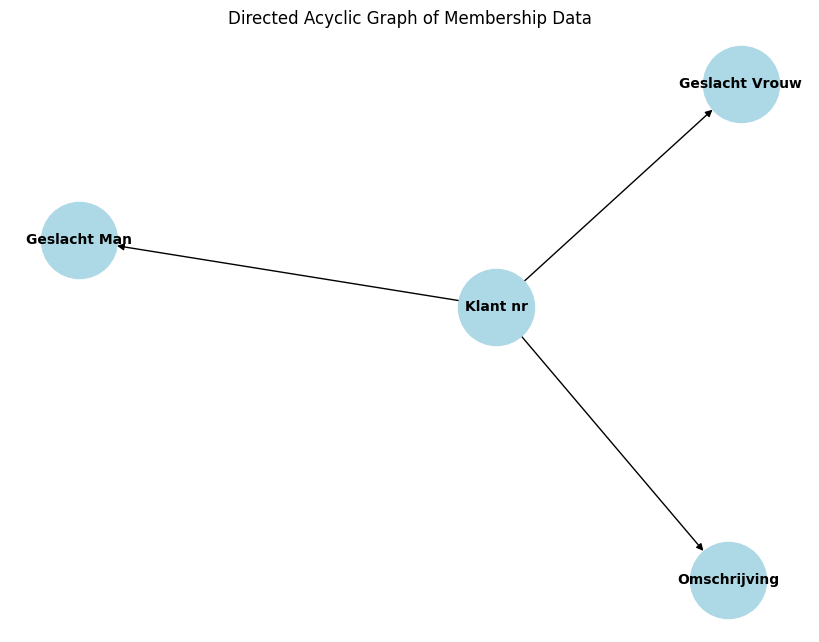

In [26]:
# Create a Directed Acyclic Graph (DAG)
G_membership = nx.DiGraph()
nodes_membership = ["Klant nr", "Geslacht Man", "Geslacht Vrouw", "Omschrijving"]
G_membership.add_nodes_from(nodes_membership)
edges_membership = [
    ("Klant nr", "Geslacht Man"),    # 'Klant nr' determines gender (man)
    ("Klant nr", "Geslacht Vrouw"),  # 'Klant nr' determines gender (vrouw)
    ("Klant nr", "Omschrijving")     # 'Klant nr' associated with membership type
]
G_membership.add_edges_from(edges_membership)

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_membership)
nx.draw(G_membership, pos, with_labels=True, node_size=3000,
        font_size=10, font_weight='bold', node_color="lightblue", arrows=True)
plt.title("Directed Acyclic Graph of Membership Data")
plt.show()



# ===============================
# 5. Load Check-In CSV Files
# ===============================


In [28]:
# Correct the last file name (assumed to be 2021-2022)
checkin_file_paths = [
    'Data/Check-in times/Check-in-times_sheet_2017-2018.csv',
    'Data/Check-in times/Check-in-times_sheet_2018-2019.csv',
    'Data/Check-in times/Check-in-times_sheet_2019-2020.csv',
    'Data/Check-in times/Check-in-times_sheet_2020-2021.csv',
    'Data/Check-in times/Check-in-times_sheet_2021- .csv'
]

checkin_dfs = []
for file in checkin_file_paths:
    try:
        df = pd.read_csv(file)
        checkin_dfs.append(df)
    except FileNotFoundError:
        print(f"File not found: {file}")

# ===============================
# 6. Combine Check-In Data and Summary
# ===============================


In [31]:
data_frames = [pd.read_csv(fp) for fp in checkin_file_paths]

# Concatenate into one DataFrame
combined_data = pd.concat(data_frames, ignore_index=True)

# Now you can print the info and summary
print("\nCombined Data Info:")
combined_data.info()
print("\nCombined Data Summary:")
print(combined_data.describe(include='all'))


Combined Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380785 entries, 0 to 380784
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   Klant nr      380785 non-null  int64 
 1   Lid id        355832 non-null  object
 2   Geslacht      380785 non-null  object
 3   Abo bezoek    373011 non-null  object
 4   Incheckdatum  380785 non-null  object
dtypes: int64(1), object(4)
memory usage: 14.5+ MB

Combined Data Summary:
             Klant nr      Lid id Geslacht              Abo bezoek  \
count   380785.000000      355832   380785                  373011   
unique            NaN         118        3                      48   
top               NaN  RUG               M  Fitness Card 2017-2018   
freq              NaN      157224   280767                   86417   
mean    191590.238121         NaN      NaN                     NaN   
std      28360.215007         NaN      NaN                     NaN   
min

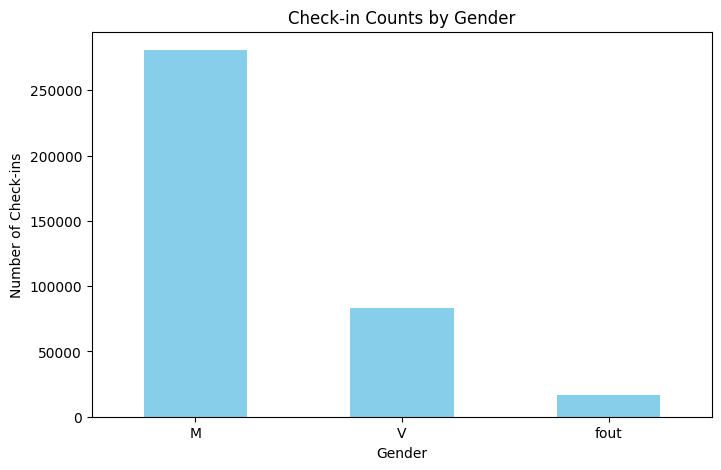

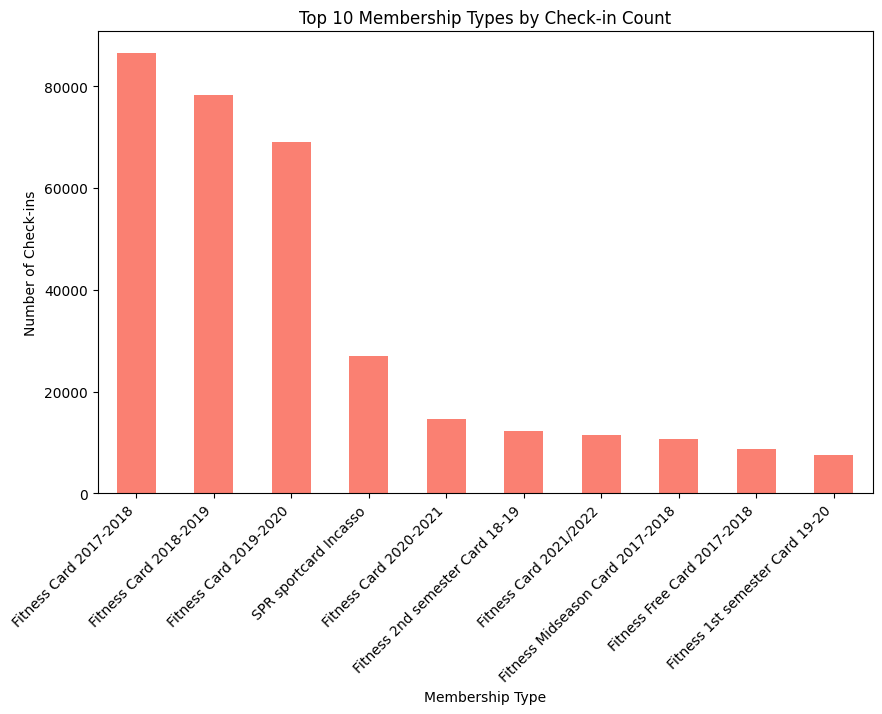

<Figure size 1200x600 with 0 Axes>

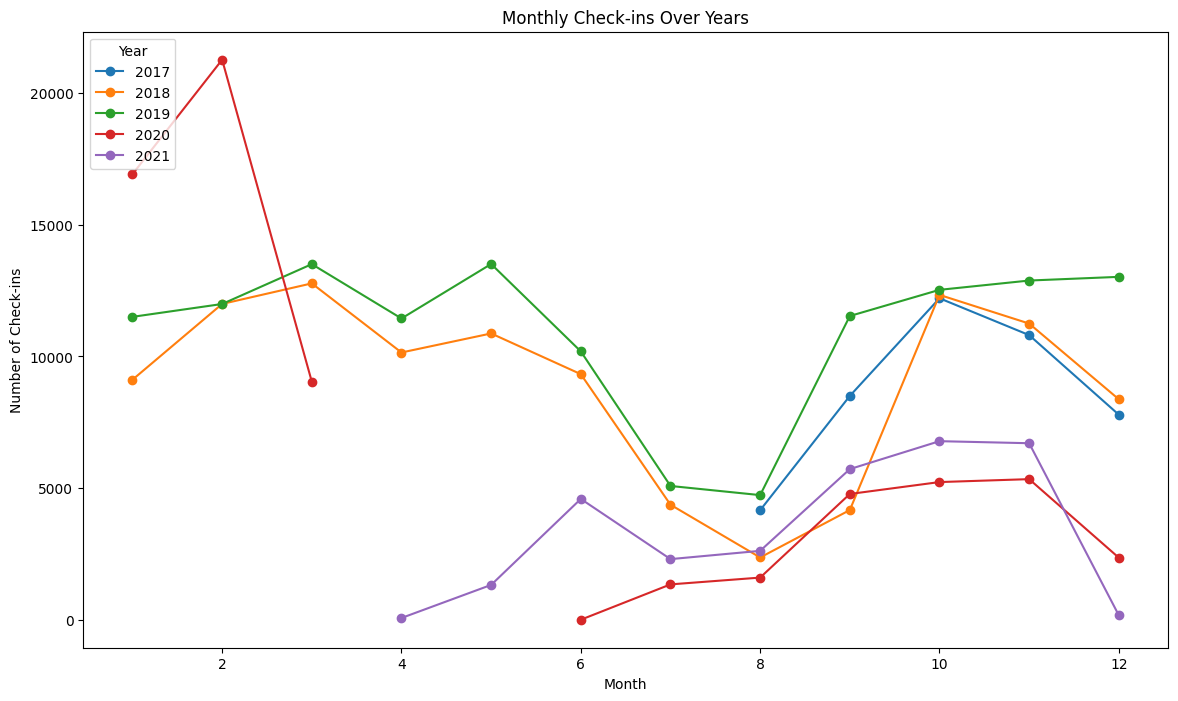

In [32]:

# Visualization 1: Check-in counts by gender
if 'Geslacht' in combined_data.columns:
    gender_counts = combined_data['Geslacht'].value_counts()
    plt.figure(figsize=(8, 5))
    gender_counts.plot(kind='bar', color='skyblue')
    plt.title('Check-in Counts by Gender')
    plt.xlabel('Gender')
    plt.ylabel('Number of Check-ins')
    plt.xticks(rotation=0)
    plt.show()
else:
    print("Column 'Geslacht' not found in combined check-in data.")

# Visualization 2: Check-in counts by membership type (Top 10)
if 'Abo bezoek' in combined_data.columns:
    membership_counts = combined_data['Abo bezoek'].value_counts().head(10)
    plt.figure(figsize=(10, 6))
    membership_counts.plot(kind='bar', color='salmon')
    plt.title('Top 10 Membership Types by Check-in Count')
    plt.xlabel('Membership Type')
    plt.ylabel('Number of Check-ins')
    plt.xticks(rotation=45, ha='right')
    plt.show()
else:
    print("Column 'Abo bezoek' not found in combined check-in data.")

# Visualization 3: Monthly Check-In Patterns
if 'Incheckdatum' in combined_data.columns:
    combined_data['Incheckdatum'] = pd.to_datetime(combined_data['Incheckdatum'], errors='coerce')
    combined_data['Year'] = combined_data['Incheckdatum'].dt.year
    combined_data['Month'] = combined_data['Incheckdatum'].dt.month

    monthly_checkins = combined_data.groupby(['Year', 'Month']).size().unstack(level=0)
    plt.figure(figsize=(12, 6))
    monthly_checkins.plot(kind='line', marker='o', figsize=(14, 8))
    plt.title('Monthly Check-ins Over Years')
    plt.xlabel('Month')
    plt.ylabel('Number of Check-ins')
    plt.legend(title='Year', loc='upper left')
    plt.show()
else:
    print("Column 'Incheckdatum' not found in combined check-in data.")

# ===============================
# 8. DAG for Check-In Data
# ===============================


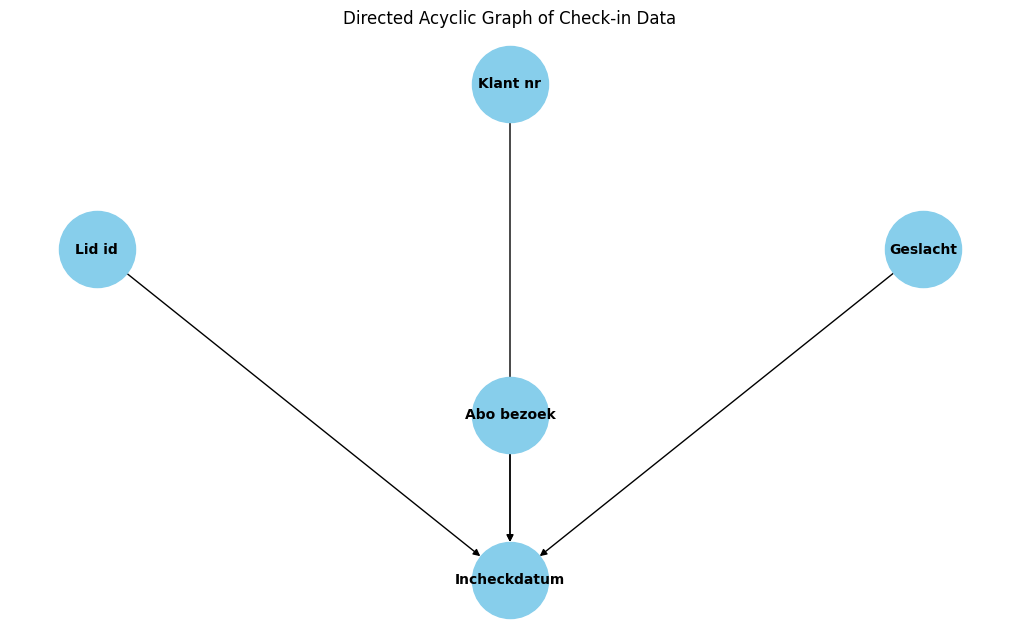

In [33]:
G_checkin = nx.DiGraph()
nodes_checkin = ["Klant nr", "Lid id", "Geslacht", "Abo bezoek", "Incheckdatum"]
G_checkin.add_nodes_from(nodes_checkin)
edges_checkin = [
    ("Klant nr", "Incheckdatum"),
    ("Lid id", "Incheckdatum"),
    ("Geslacht", "Incheckdatum"),
    ("Abo bezoek", "Incheckdatum")
]
G_checkin.add_edges_from(edges_checkin)

plt.figure(figsize=(10, 6))
pos_checkin = {
    "Klant nr": (0, 1),
    "Lid id": (-1, 0),
    "Geslacht": (1, 0),
    "Abo bezoek": (0, -1),
    "Incheckdatum": (0, -2)
}
nx.draw(G_checkin, pos_checkin, with_labels=True, node_size=3000,
        node_color="skyblue", font_size=10, font_weight="bold", arrows=True)
plt.title("Directed Acyclic Graph of Check-in Data")
plt.show()

In [37]:
if 'Geslacht Man' in combined_data.columns or 'Geslacht Vrouw' in combined_data.columns:
    # Use the binary flags if available
    combined_data['Geslacht'] = np.where(
        (combined_data.get('Geslacht Man', pd.Series(0)).astype(bool)),
        'Man',
        np.where(combined_data.get('Geslacht Vrouw', pd.Series(0)).astype(bool),
                 'Vrouw', combined_data.get('Geslacht', 'Unknown'))
    )
    # Optionally drop the old columns if they exist
    combined_data.drop(columns=[col for col in ['Geslacht Man', 'Geslacht Vrouw'] if col in combined_data.columns],
                       inplace=True)
else:
    print("No separate gender columns found; using existing 'Geslacht' column if available.")

# If you have a merged DataFrame from multiple sources, you might call it merged_df.
merged_df = combined_data.copy()  # For subsequent analysis
print(combined_data.columns)


No separate gender columns found; using existing 'Geslacht' column if available.
Index(['Klant nr', 'Lid id', 'Geslacht', 'Abo bezoek', 'Incheckdatum', 'Year',
       'Month'],
      dtype='object')


In [38]:
if 'Incheckdatum' in merged_df.columns:
    merged_df['Incheckdatum'] = pd.to_datetime(merged_df['Incheckdatum'], errors='coerce')
    merged_df['Year'] = merged_df['Incheckdatum'].dt.year
    merged_df['Month'] = merged_df['Incheckdatum'].dt.month
    merged_df['Day'] = merged_df['Incheckdatum'].dt.day
    merged_df['Weekday'] = merged_df['Incheckdatum'].dt.day_name()
    merged_df['Is_Weekend'] = merged_df['Weekday'].isin(['Saturday', 'Sunday'])
    # Uncomment to preview:
    # print(merged_df[['Incheckdatum', 'Year', 'Month', 'Day', 'Weekday', 'Is_Weekend']].head())
else:
    print("Column 'Incheckdatum' not found in merged data.")


In [39]:

exam_periods = {
    '2017-2018': [
        ('2017-10-30', '2017-11-10'),
        ('2018-01-14', '2018-02-01'),
        ('2018-03-25', '2018-04-12'),
        ('2018-06-11', '2018-06-29'),
        ('2018-07-02', '2018-07-13')
    ],
    '2018-2019': [
        ('2018-10-29', '2018-11-09'),
        ('2019-01-15', '2019-02-02'),
        ('2019-03-26', '2019-04-13'),
        ('2019-06-11', '2019-06-28')
    ],
    '2019-2020': [
        ('2019-10-28', '2019-11-08'),
        ('2020-01-13', '2020-01-31'),
        ('2020-03-23', '2020-03-31'),
        ('2020-06-08', '2020-06-10')
    ],
    '2020-2021': [
        ('2020-08-17', '2020-08-28'),
        ('2020-10-26', '2020-11-06'),
        ('2021-01-11', '2021-01-29'),
        ('2021-03-22', '2021-04-09'),
        ('2021-06-07', '2021-06-25')
    ],
    '2021-2022': [
        ('2021-11-01', '2021-11-12'),
        ('2022-01-17', '2022-02-04'),
        ('2022-03-28', '2022-04-14'),
        ('2022-06-13', '2022-07-01')
    ]
}

if 'Incheckdatum' in merged_df.columns:
    # Precompute exam period ranges
    exam_period_ranges = []
    for periods in exam_periods.values():
        for start, end in periods:
            exam_period_ranges.append((pd.Timestamp(start), pd.Timestamp(end)))
    exam_period_df = pd.DataFrame(exam_period_ranges, columns=['Start', 'End'])
    
    def check_exam_period(dates):
        is_exam = pd.Series(False, index=dates.index)
        for _, row in exam_period_df.iterrows():
            is_exam |= (dates >= row['Start']) & (dates <= row['End'])
        return is_exam
    
    merged_df['Exam_Period'] = check_exam_period(merged_df['Incheckdatum'])
else:
    print("Column 'Incheckdatum' not found; cannot compute exam periods.")

In [40]:

# Aggregate the data by date to get the number of visitors per day
if 'Incheckdatum' in merged_df.columns:
    daily_visitors = merged_df.groupby('Incheckdatum').size()
    X = np.array(daily_visitors.index.map(pd.Timestamp.toordinal)).reshape(-1, 1)
    y = daily_visitors.values
    
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
    }
    
    results = {}
    for model_name, model in models.items():
        model.fit(X, y)
        y_pred = model.predict(X)
        r2 = r2_score(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        results[model_name] = {"R² Score": r2, "RMSE": rmse}
    
    print("\nVisitor Prediction Model Evaluation:")
    for model_name, metrics in results.items():
        print(f"{model_name}:")
        print(f"  R² Score: {metrics['R² Score']:.4f}")
        print(f"  RMSE: {metrics['RMSE']:.4f}")
else:
    print("Column 'Incheckdatum' missing; cannot run visitor prediction models.")


Visitor Prediction Model Evaluation:
Linear Regression:
  R² Score: 0.0215
  RMSE: 0.2623
Decision Tree:
  R² Score: 0.6477
  RMSE: 0.1574
Random Forest:
  R² Score: 0.6477
  RMSE: 0.1574


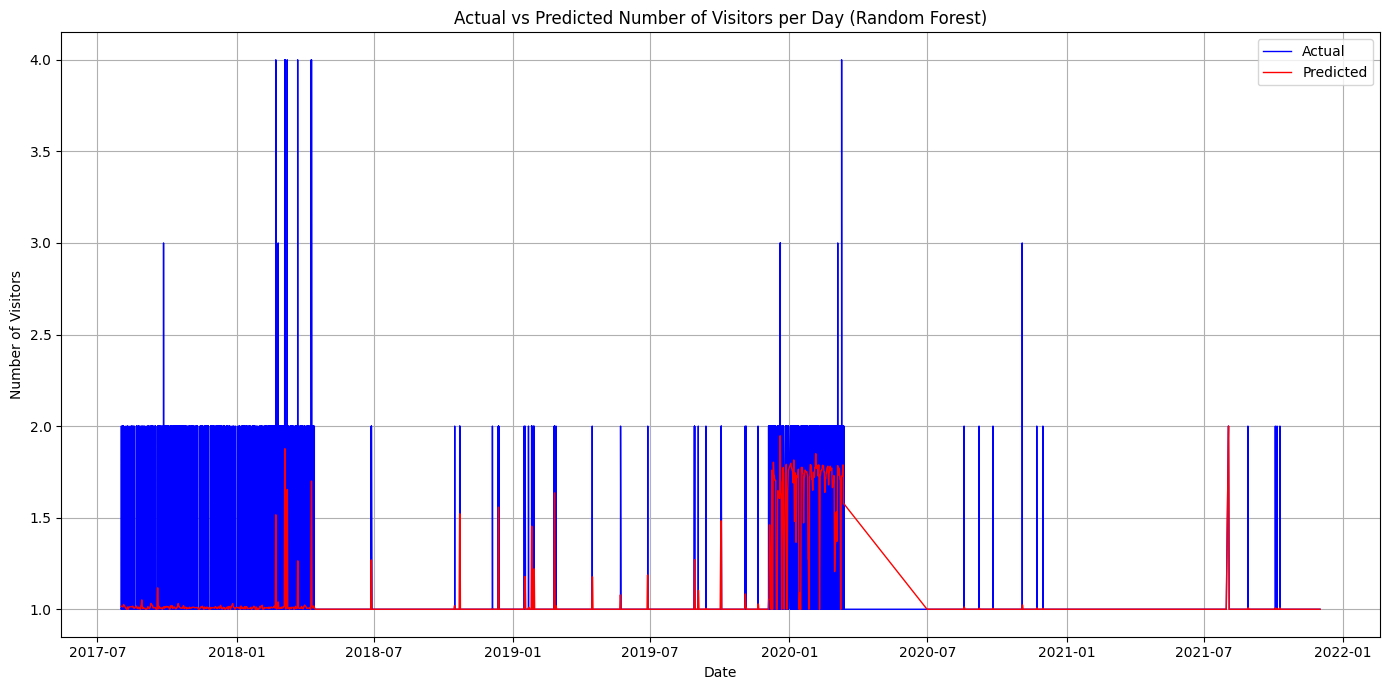

In [41]:
if 'Incheckdatum' in merged_df.columns:
    daily_visitors = merged_df.groupby('Incheckdatum').size()
    X = np.array(daily_visitors.index.map(pd.Timestamp.toordinal)).reshape(-1, 1)
    y = daily_visitors.values
    
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X, y)
    y_pred = rf_model.predict(X)
    
    plt.figure(figsize=(14, 7))
    plt.plot(daily_visitors.index, y, color='blue', linewidth=1, label='Actual')
    plt.plot(daily_visitors.index, y_pred, color='red', linewidth=1, label='Predicted')
    plt.title('Actual vs Predicted Number of Visitors per Day (Random Forest)')
    plt.xlabel('Date')
    plt.ylabel('Number of Visitors')
    plt.legend(loc='best')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Column 'Incheckdatum' missing; cannot plot visitor predictions.")

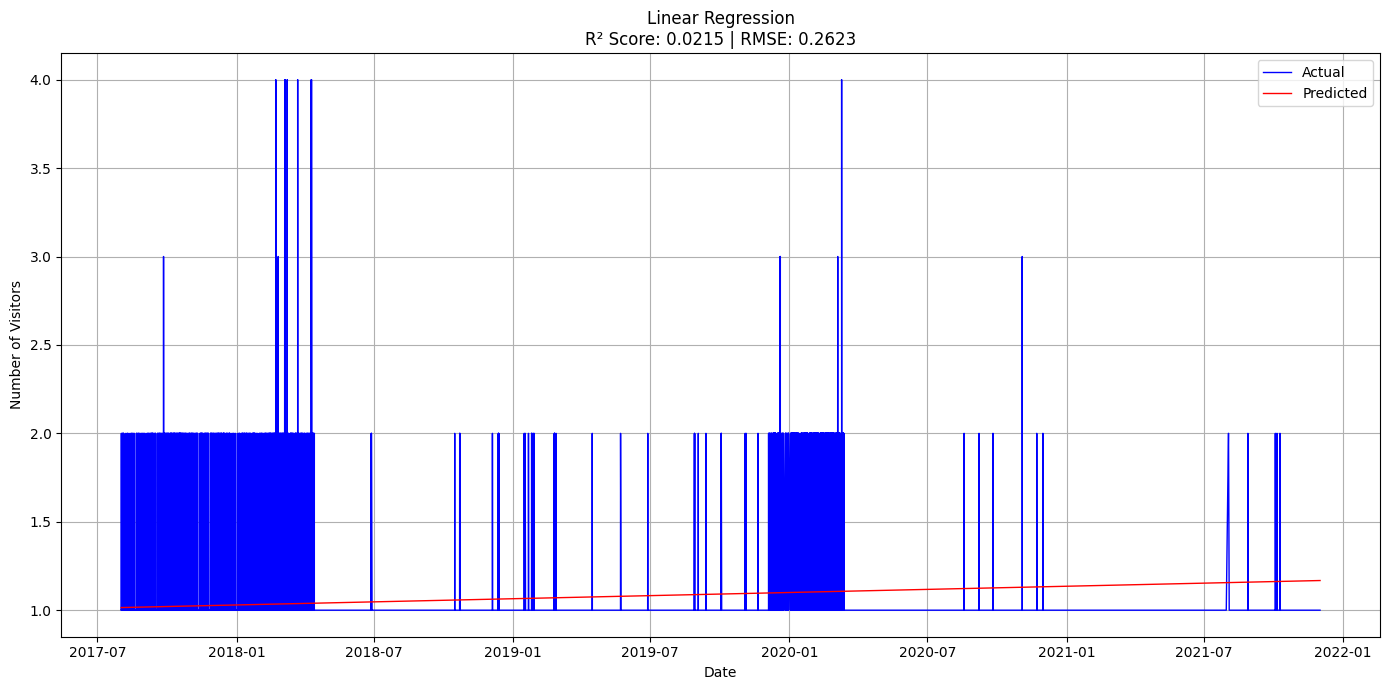

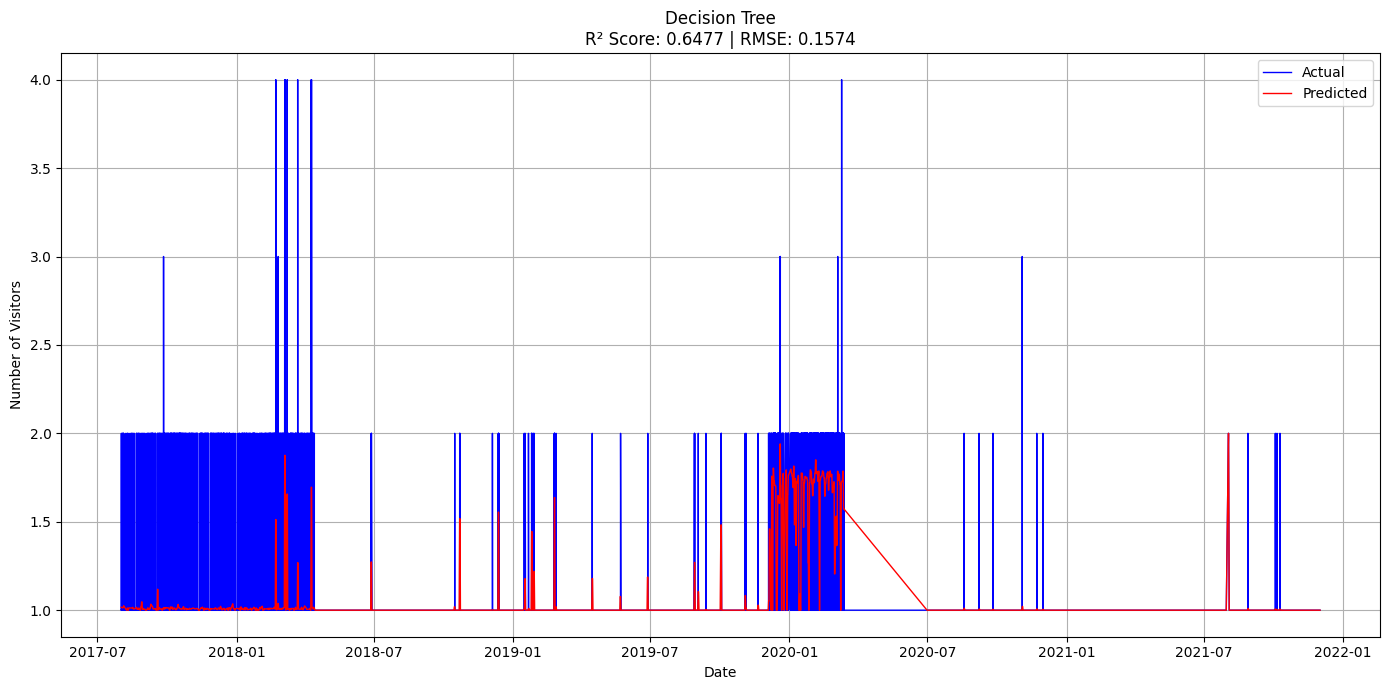

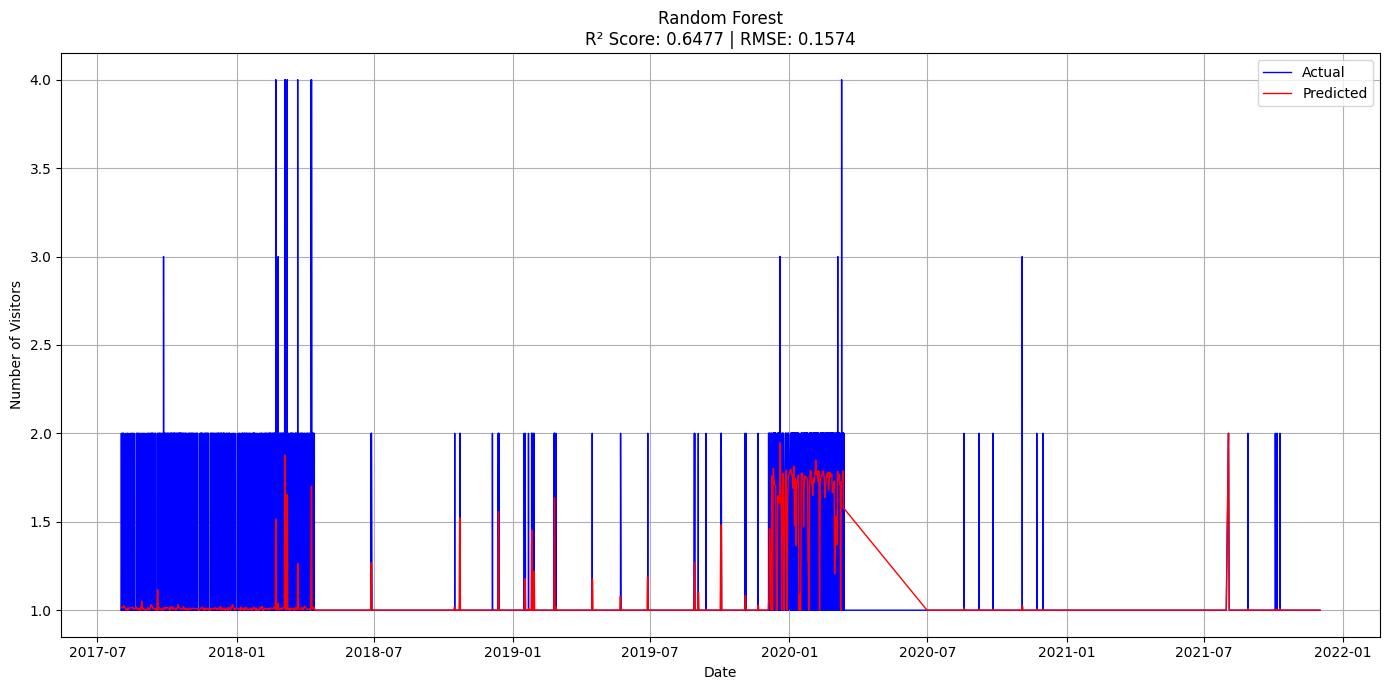

In [42]:
if 'Incheckdatum' in merged_df.columns:
    # Aggregate data by date
    daily_visitors = merged_df.groupby('Incheckdatum').size()
    X = np.array(daily_visitors.index.map(pd.Timestamp.toordinal)).reshape(-1, 1)
    y = daily_visitors.values

    # Define models to evaluate
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
    }

    # Loop through each model, fit, predict, and plot the results
    for model_name, model in models.items():
        model.fit(X, y)
        y_pred = model.predict(X)
        r2 = r2_score(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))

        # Create a new figure for each model's predictions
        plt.figure(figsize=(14, 7))
        plt.plot(daily_visitors.index, y, color='blue', linewidth=1, label='Actual')
        plt.plot(daily_visitors.index, y_pred, color='red', linewidth=1, label='Predicted')
        plt.title(f"{model_name}\nR² Score: {r2:.4f} | RMSE: {rmse:.4f}")
        plt.xlabel('Date')
        plt.ylabel('Number of Visitors')
        plt.legend(loc='best')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("Column 'Incheckdatum' missing; cannot run visitor prediction models.")
